In [13]:
import zipfile
import os

zip_path = r"C:\Users\HP\Downloads\archive (4).zip"

extract_folder = r"C:\Users\HP\Downloads\Churn_Data"

os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_folder)

print("Dataset extracted successfully!")

print(os.listdir(extract_folder))

Dataset extracted successfully!
['ecommerce_analysis.ipynb', 'ecommerce_customer_data_large.csv']


In [14]:
import os 

folder = r'C:\Users\HP\Downloads\Churn_Data'

for root, dirs, files in os.walk(folder):
    for file in files:
        print(file)

ecommerce_analysis.ipynb
ecommerce_customer_data_large.csv


In [15]:
import pandas as pd 
import numpy as np

df=pd.read_csv(r"C:\Users\HP\Downloads\Churn_Data\ecommerce_customer_data_large.csv")

print("Dataset Loaded Successfully!")



Dataset Loaded Successfully!


In [17]:
print(df.head())
print(df.shape)
print(df.describe())
print(df.info())

   Customer ID        Purchase Date Product Category  Product Price  Quantity  \
0        44605  2023-05-03 21:30:02             Home            177         1   
1        44605  2021-05-16 13:57:44      Electronics            174         3   
2        44605  2020-07-13 06:16:57            Books            413         1   
3        44605  2023-01-17 13:14:36      Electronics            396         3   
4        44605  2021-05-01 11:29:27            Books            259         4   

   Total Purchase Amount Payment Method  Customer Age  Returns Customer Name  \
0                   2427         PayPal            31      1.0   John Rivera   
1                   2448         PayPal            31      1.0   John Rivera   
2                   2345    Credit Card            31      1.0   John Rivera   
3                    937           Cash            31      0.0   John Rivera   
4                   2598         PayPal            31      1.0   John Rivera   

   Age  Gender  Churn  
0   31  

In [19]:
df.columns
df.isnull().sum()
df.duplicated().sum()
df.dtypes

print('Total Rows:',df.shape[0])
print('Total Columns:',df.shape[1])
print('Total Missing Values:',
      df.isnull().sum().sum())

print('Total Duplicate Rows Rows:',
      df.duplicated().sum())

Total Rows: 250000
Total Columns: 13
Total Missing Values: 47382
Total Duplicate Rows Rows: 0


In [29]:
missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_data = missing_data.sort_values(
    by="Missing Values",
    ascending=False
)

print(missing_data)

                       Missing Values  Percentage
Returns                         47382     18.9528
Purchase Date                       0      0.0000
Product Category                    0      0.0000
Product Price                       0      0.0000
Customer ID                         0      0.0000
Quantity                            0      0.0000
Total Purchase Amount               0      0.0000
Payment Method                      0      0.0000
Customer Age                        0      0.0000
Customer Name                       0      0.0000
Age                                 0      0.0000
Gender                              0      0.0000
Churn                               0      0.0000


Customer ID                int64
Purchase Date                str
Product Category             str
Product Price              int64
Quantity                   int64
Total Purchase Amount      int64
Payment Method               str
Customer Age               int64
Returns                  float64
Customer Name                str
Age                        int64
Gender                       str
Churn                      int64
dtype: object


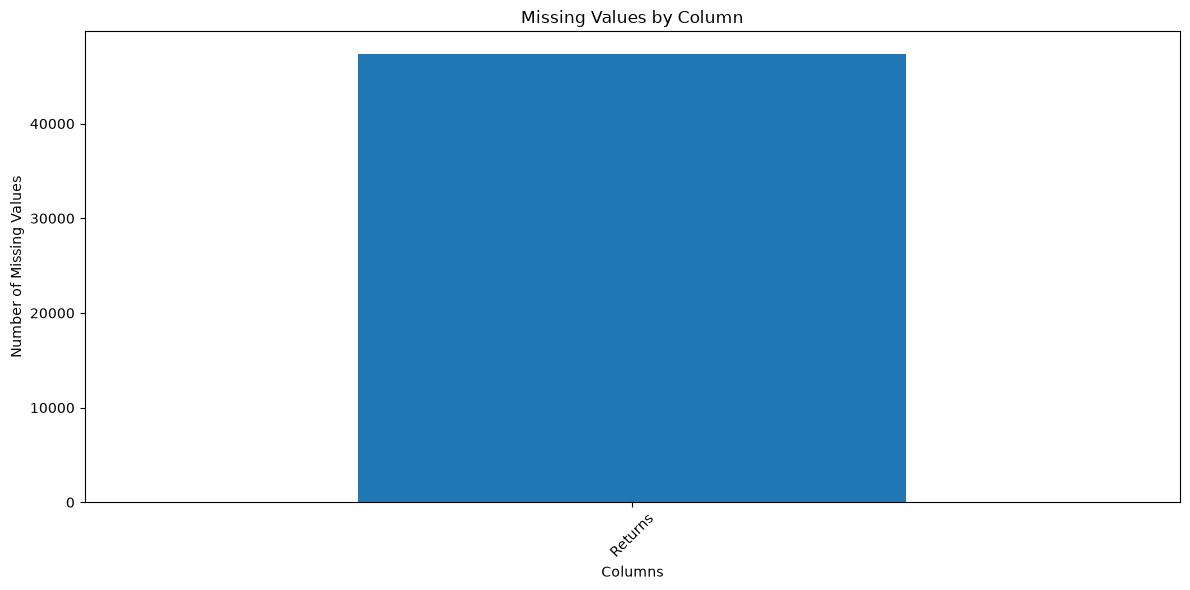

Churn
0    199870
1     50130
Name: count, dtype: int64
Churn
0    79.948
1    20.052
Name: proportion, dtype: float64


In [33]:
print(df.dtypes)
import matplotlib.pyplot as plt

missing = df.isnull().sum()

missing = missing[missing > 0]

plt.figure(figsize=(12, 6))

missing.plot(kind='bar')

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(df['Churn'].value_counts())

print(df['Churn'].value_counts(normalize=True) * 100)

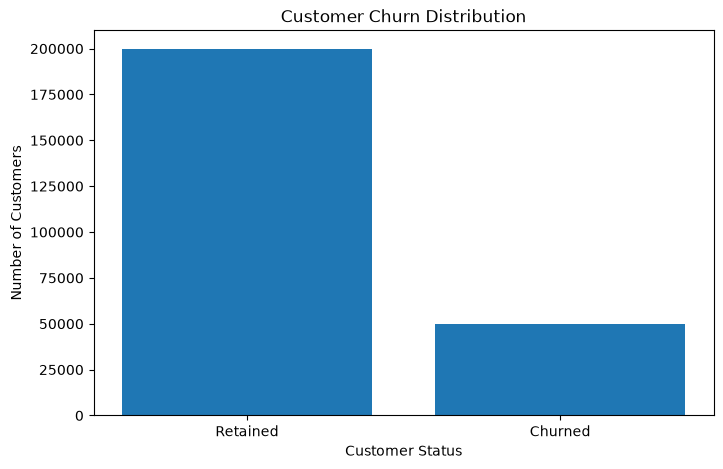

['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Age', 'Gender', 'Churn']


In [34]:
import matplotlib.pyplot as plt

churn_counts = df['Churn'].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    ['Retained', 'Churned'],
    [churn_counts[0], churn_counts[1]]
)

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.show()
print(df.columns.tolist())

         count    sum      mean  Churn Rate (%)
Gender                                         
Female  124324  25067  0.201626       20.162640
Male    125676  25063  0.199426       19.942551
Payment Method
Cash           20.252494
PayPal         20.243046
Credit Card    19.661987
Name: Churn, dtype: float64
Age Group
18-25    21.060598
26-35    19.437560
36-45    19.818473
46-55    19.460576
55+      20.456848
Name: Churn, dtype: float64


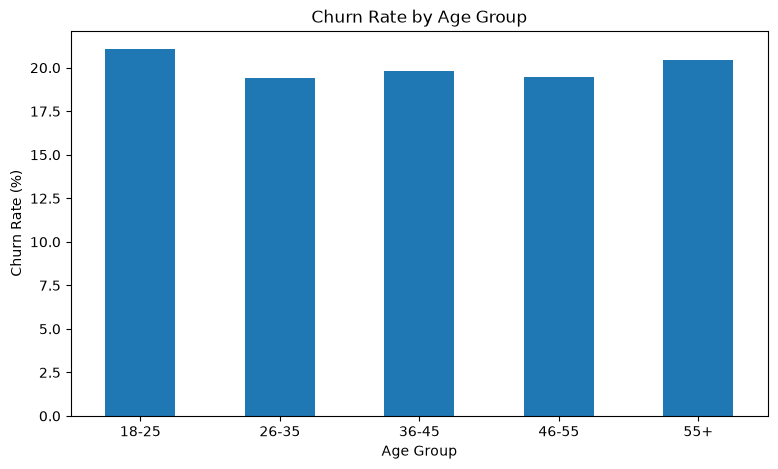

In [35]:
gender_churn = df.groupby('Gender')['Churn'].agg(
    ['count', 'sum', 'mean']
)

gender_churn['Churn Rate (%)'] = gender_churn['mean'] * 100

print(gender_churn)
payment_churn = df.groupby('Payment Method')['Churn'].mean() * 100

print(payment_churn.sort_values(ascending=False))
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 25, 35, 45, 55, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '55+']
)

age_churn = df.groupby(
    'Age Group', observed=False
)['Churn'].mean() * 100

print(age_churn)
age_churn.plot(kind='bar', figsize=(9, 5))

plt.title('Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

                  count    sum      mean  Churn Rate (%)
Product Category                                        
Clothing          62581  12593  0.201227       20.122721
Books             62247  12499  0.200797       20.079683
Electronics       62630  12553  0.200431       20.043110
Home              62542  12485  0.199626       19.962585
          count      mean  Churn Rate (%)
Returns                                  
0.0      101142  0.202725       20.272488
1.0      101476  0.199456       19.945603


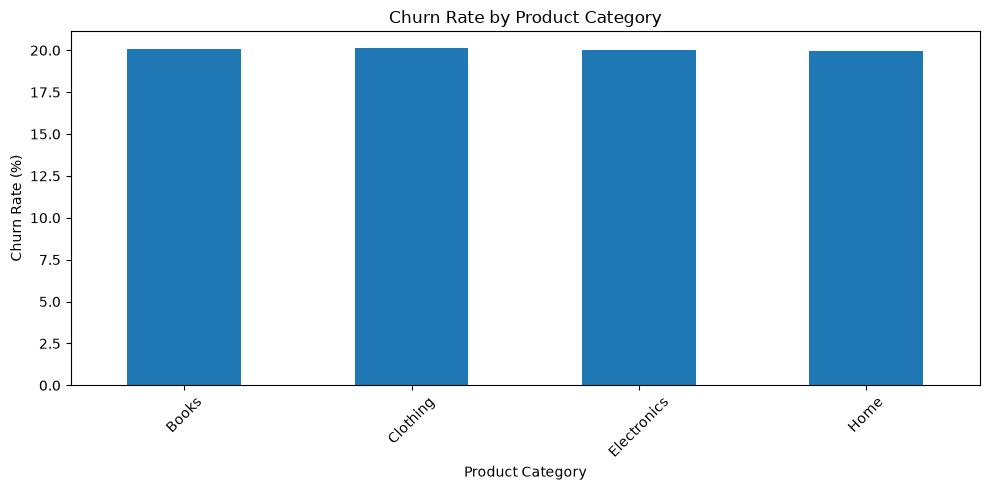

In [36]:
category_churn = df.groupby(
    'Product Category'
)['Churn'].agg(['count', 'sum', 'mean'])

category_churn['Churn Rate (%)'] = (
    category_churn['mean'] * 100
)

print(category_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
))

returns_churn = df.groupby(
    'Returns'
)['Churn'].agg(['count', 'mean'])

returns_churn['Churn Rate (%)'] = (
    returns_churn['mean'] * 100
)

print(returns_churn)

category_churn['Churn Rate (%)'].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Churn Rate by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

       Product Price  Quantity  Total Purchase Amount
Churn                                                
0         254.658868  3.005894            2724.875439
1         255.077060  3.001117            2727.417614


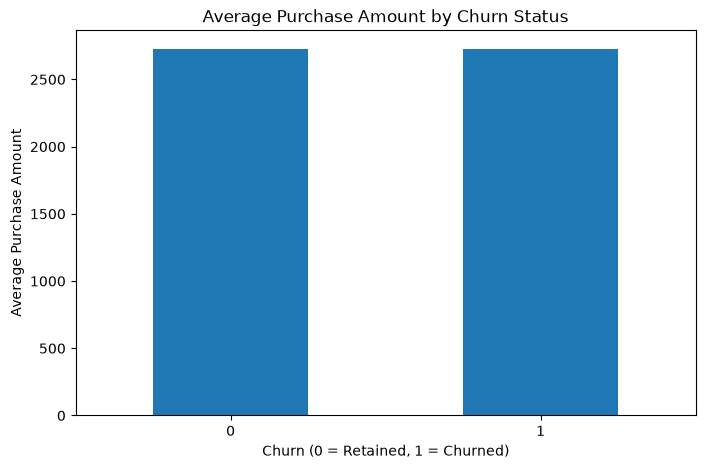

Analysis copy created successfully!
(250000, 14)


In [37]:
purchase_analysis = df.groupby('Churn').agg({
    'Product Price': 'mean',
    'Quantity': 'mean',
    'Total Purchase Amount': 'mean'
})

print(purchase_analysis)

purchase_analysis['Total Purchase Amount'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Purchase Amount by Churn Status')
plt.xlabel('Churn (0 = Retained, 1 = Churned)')
plt.ylabel('Average Purchase Amount')
plt.xticks(rotation=0)
plt.show()

df_analysis = df.copy()

print("Analysis copy created successfully!")
print(df_analysis.shape)

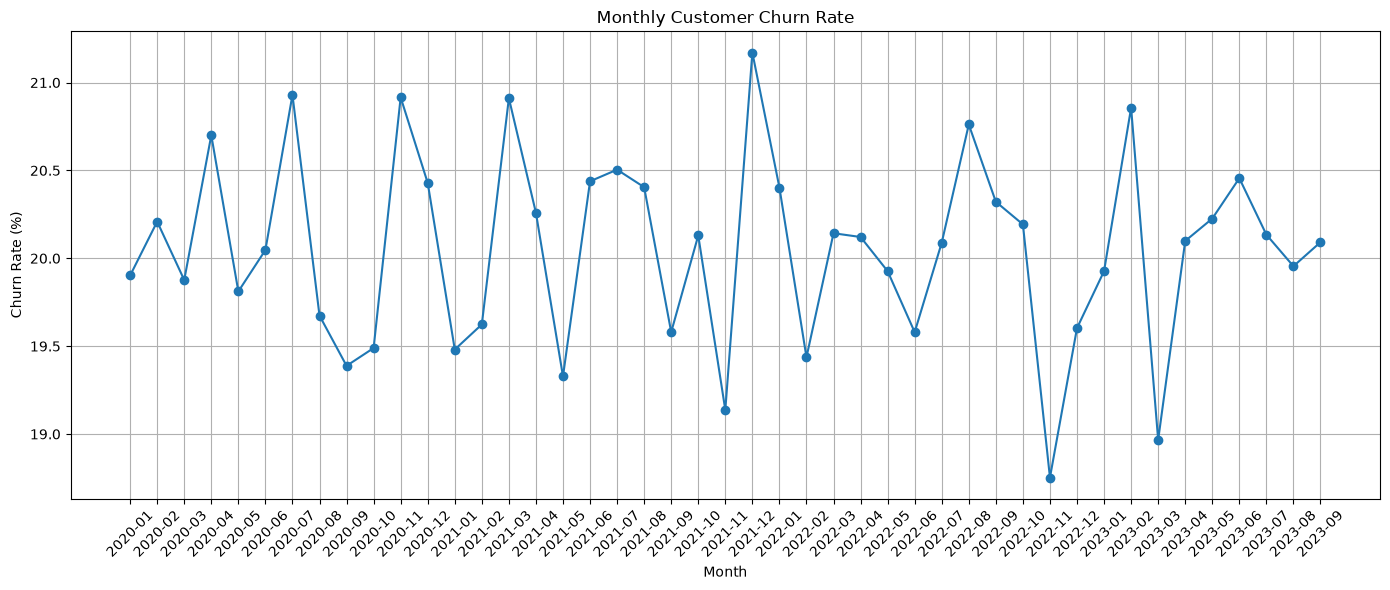

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

df['Purchase Date'] = pd.to_datetime(
    df['Purchase Date'], errors='coerce'
)

monthly_churn = (
    df.dropna(subset=['Purchase Date'])
    .assign(Month=lambda x: x['Purchase Date'].dt.to_period('M'))
    .groupby('Month')['Churn']
    .mean() * 100
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_churn.index.astype(str),
    monthly_churn.values,
    marker='o'
)

plt.title('Monthly Customer Churn Rate')
plt.xlabel('Month')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

Payment Method
Cash           20.252494
Credit Card    19.661987
PayPal         20.243046
Name: Churn, dtype: float64


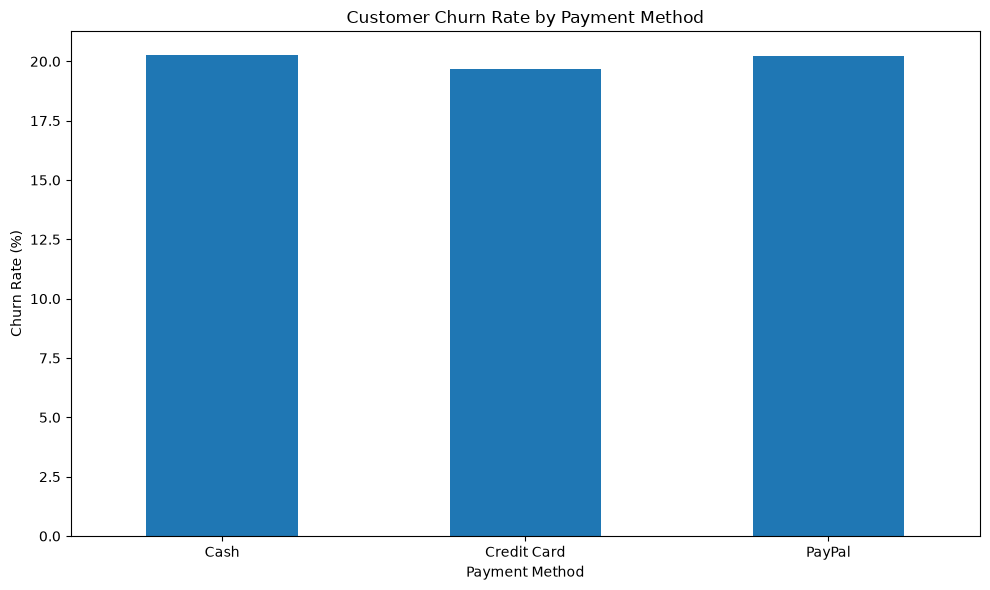

In [39]:
payment_churn = df.groupby('Payment Method')['Churn'].mean() * 100

print(payment_churn)

plt.figure(figsize=(10, 6))

payment_churn.plot(kind='bar')

plt.title('Customer Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Gender
Female    20.162640
Male      19.942551
Name: Churn, dtype: float64


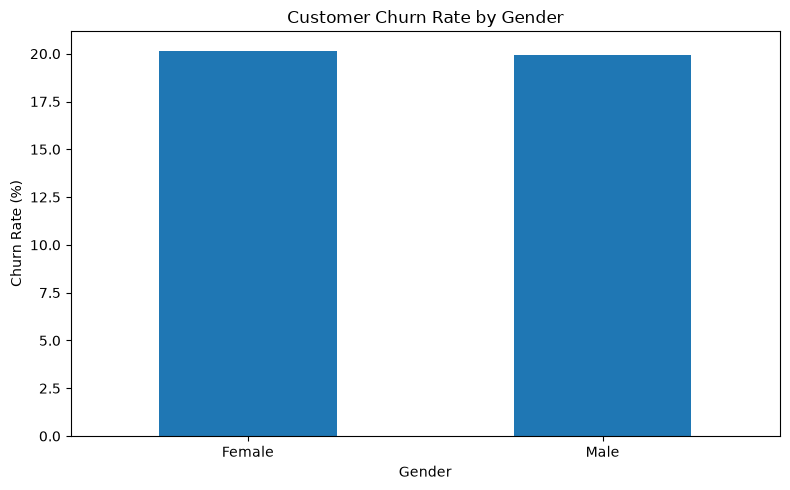

In [40]:
gender_churn = df.groupby('Gender')['Churn'].mean() * 100

print(gender_churn)

plt.figure(figsize=(8, 5))

gender_churn.plot(kind='bar')

plt.title('Customer Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Price Range
0-100      19.765991
101-200    19.921023
201-300    20.368732
301-400    20.293461
401-500    19.884772
Name: Churn, dtype: float64


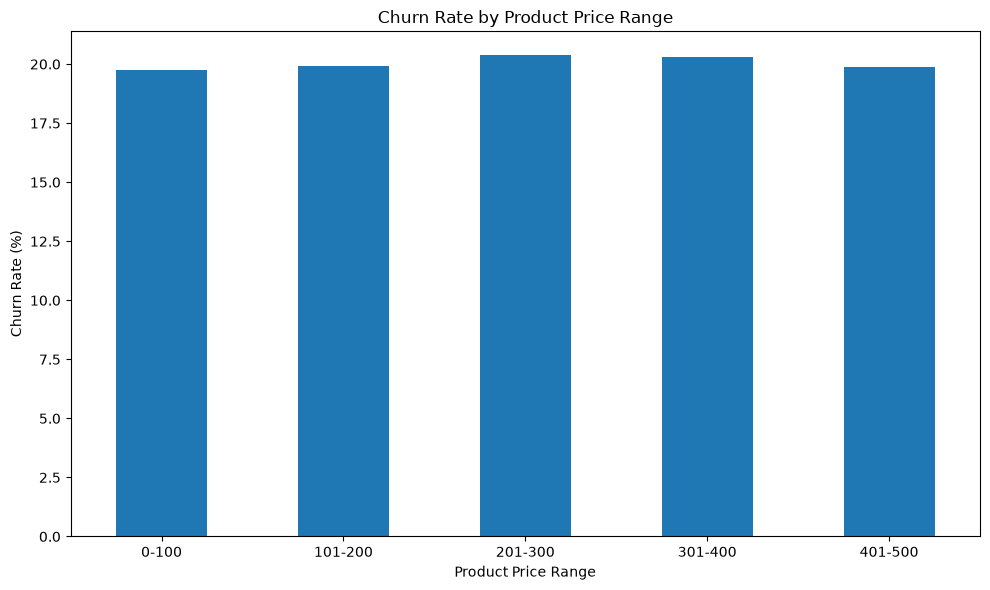

In [41]:
df['Price Range'] = pd.cut(
    df['Product Price'],
    bins=[0, 100, 200, 300, 400, 500],
    labels=['0-100', '101-200', '201-300', '301-400', '401-500']
)

price_churn = df.groupby(
    'Price Range', observed=True
)['Churn'].mean() * 100

print(price_churn)

plt.figure(figsize=(10, 6))

price_churn.plot(kind='bar')

plt.title('Churn Rate by Product Price Range')
plt.xlabel('Product Price Range')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Quantity Group
1    20.108641
2    20.048304
3    20.119326
4    20.085155
5    19.899239
Name: Churn, dtype: float64


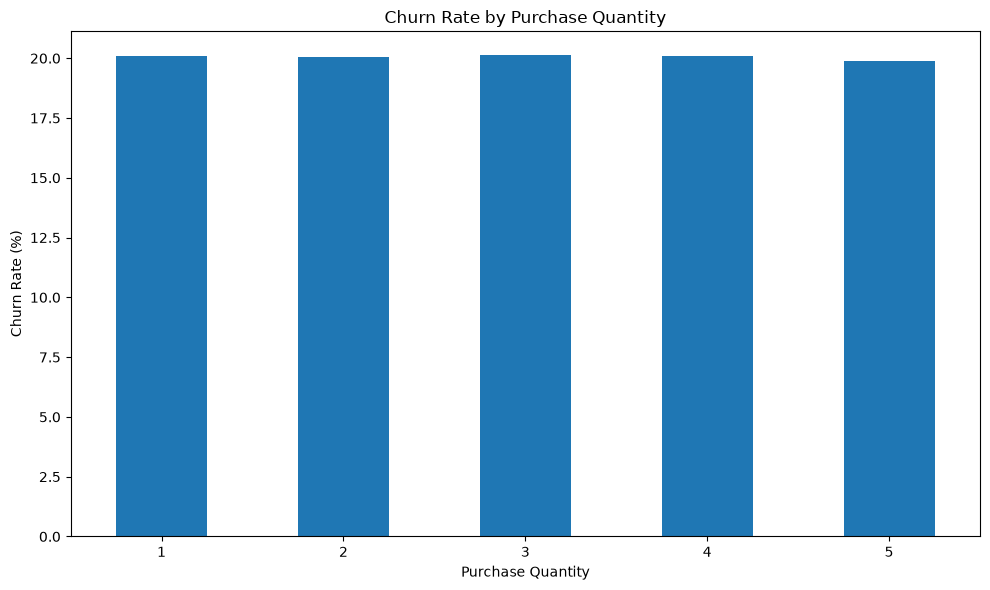

In [42]:
df['Quantity Group'] = pd.cut(
    df['Quantity'],
    bins=[0, 1, 2, 3, 4, 5, float('inf')],
    labels=['1', '2', '3', '4', '5', 'Above 5']
)

quantity_churn = (
    df.groupby('Quantity Group', observed=True)['Churn'].mean() * 100
)

print(quantity_churn)

plt.figure(figsize=(10, 6))

quantity_churn.plot(kind='bar')

plt.title('Churn Rate by Purchase Quantity')
plt.xlabel('Purchase Quantity')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

          Total Purchase Amount  Quantity  Product Price
Retained            2724.875439  3.005894     254.658868
Churned             2727.417614  3.001117     255.077060


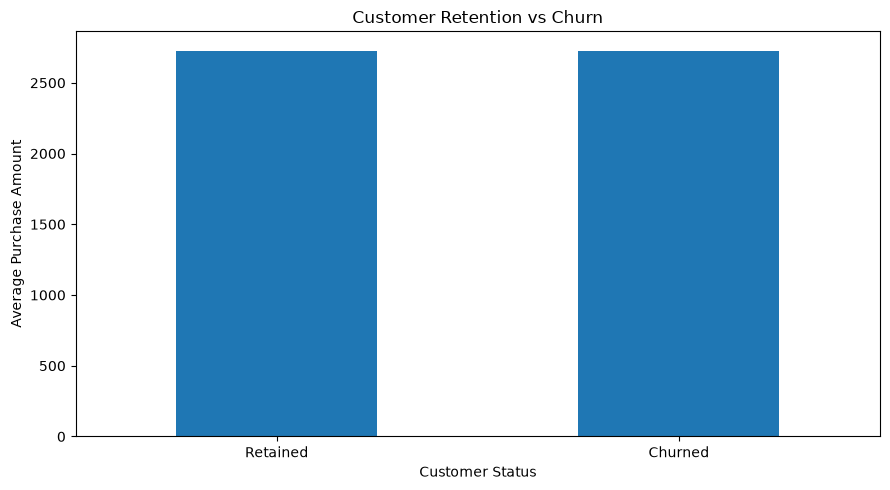

In [43]:
retention_analysis = df.groupby('Churn').agg({
    'Total Purchase Amount': 'mean',
    'Quantity': 'mean',
    'Product Price': 'mean'
})

retention_analysis.index = ['Retained', 'Churned']

print(retention_analysis)

plt.figure(figsize=(9, 5))

retention_analysis['Total Purchase Amount'].plot(
    kind='bar'
)

plt.title('Customer Retention vs Churn')
plt.xlabel('Customer Status')
plt.ylabel('Average Purchase Amount')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

             Total Purchase Amount  Total Purchases
Customer ID                                        
1                             6290                3
2                            16481                6
3                             9423                4
4                             7826                5
5                             9769                5
Customer Segment
Medium Value    16558
Low Value       16554
High Value      16549
Name: count, dtype: int64


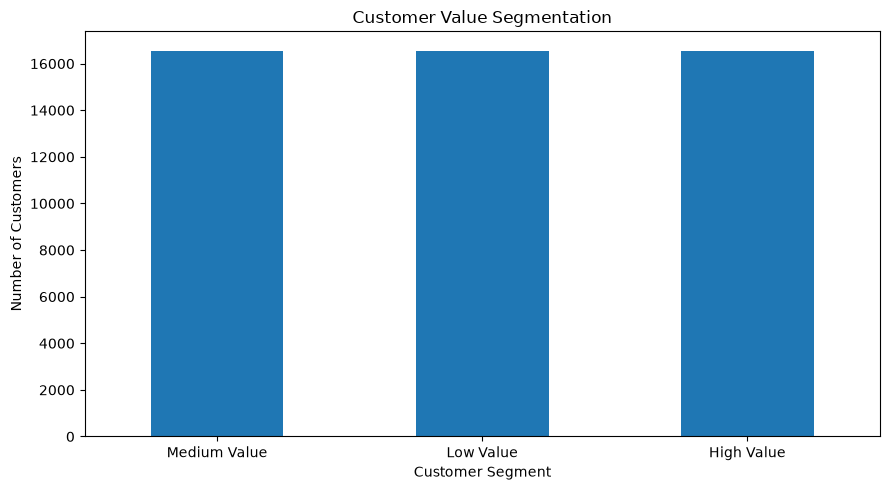

In [44]:
clv_analysis = df.groupby('Customer ID').agg({
    'Total Purchase Amount': 'sum',
    'Purchase Date': 'count'
})

clv_analysis.rename(
    columns={'Purchase Date': 'Total Purchases'},
    inplace=True
)

print(clv_analysis.head())

clv_analysis['Customer Segment'] = pd.qcut(
    clv_analysis['Total Purchase Amount'],
    q=3,
    labels=['Low Value', 'Medium Value', 'High Value']
)

print(clv_analysis['Customer Segment'].value_counts())

clv_analysis['Customer Segment'].value_counts().plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Customer Value Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

                       Customer ID  Product Price  Quantity  \
Customer ID                    1.0           -0.0      -0.0   
Product Price                 -0.0            1.0       0.0   
Quantity                      -0.0            0.0       1.0   
Total Purchase Amount          0.0           -0.0       0.0   
Customer Age                   0.0            0.0      -0.0   
Returns                        0.0            0.0       0.0   
Age                            0.0            0.0      -0.0   
Churn                          0.0            0.0      -0.0   

                       Total Purchase Amount  Customer Age  Returns   Age  \
Customer ID                             0.00          0.00      0.0  0.00   
Product Price                          -0.00          0.00      0.0  0.00   
Quantity                                0.00         -0.00      0.0 -0.00   
Total Purchase Amount                   1.00          0.06      0.0  0.06   
Customer Age                            0.06   

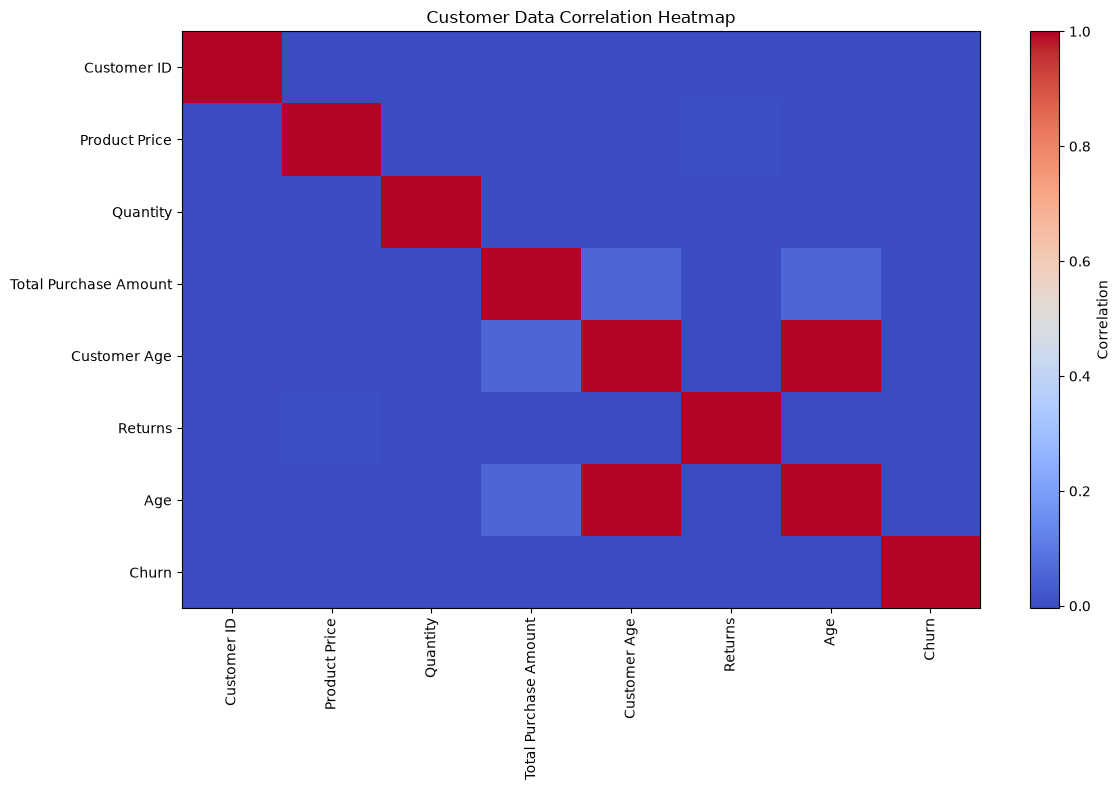

In [45]:
import numpy as np
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

print(correlation.round(2))

plt.figure(figsize=(12, 8))

plt.imshow(correlation, cmap='coolwarm', aspect='auto')

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title('Customer Data Correlation Heatmap')

plt.tight_layout()
plt.show()

In [48]:
df.to_csv(
    r"C:\Users\HP\Downloads\Churn_Data\Customer_Churn_Analysis.csv",
    index=False
)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


NameError: name 'X' is not defined